Pending: 

Escribir en un archivo csv o similar el dataFrame 

Quitar uncertain values (no muy importante y quitar pocos)

# Bootcamp Session 2: Cleaning the Data


In [67]:
import numpy as np
import matplotlib.pyplot as plt
import pandas

In [155]:
df = pandas.read_csv("ZooSpecPhoto_jtortosavalero.csv")

In [156]:
df

,specobjid,objid,dr7objid,ra,dec,rastring,decstring,nvote,p_el,p_cw,...,secTarget,extinction_u,extinction_g,extinction_r,extinction_i,extinction_z,htmID,fieldID,Column4,size
0,477461031975675904,1237649918430937304,587724197206032534,19.91775,13.36675,01:19:40.26,+13:22:00.3,33,0.424,0.485,...,0,0.247012,0.181749,0.131819,0.099955,0.070869,17306906654567,587724197206032384,119568270075363328,5.496789
1,477449761981491200,1237649918431199302,587724197206294600,20.41158,13.23469,01:21:38.78,+13:14:04.9,30,0.667,0.100,...,0,0.203788,0.149946,0.108753,0.082464,0.058468,17308112457260,587724197206294528,119568269903396864,3.948890
2,477449487103584256,1237649918431199389,587724197206294626,20.49779,13.41939,01:21:59.47,+13:25:09.8,27,0.815,0.000,...,0,0.187910,0.138262,0.100279,0.076039,0.053912,17308095755797,587724197206294528,119568269899202560,2.198422
3,477439041743120384,1237649918431264867,587724197206360172,20.59342,13.36708,01:22:22.42,+13:22:01.5,35,0.143,0.000,...,0,0.190419,0.140109,0.101619,0.077054,0.054632,17308094626202,587724197206360064,119568269739819008,6.074496
4,477437942231492608,1237649918431264925,587724197206360253,20.63079,13.40881,01:22:31.39,+13:24:31.7,30,0.733,0.000,...,0,0.184785,0.135963,0.098612,0.074774,0.053016,17308084823579,587724197206360064,119568269723041792,5.560807
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
659267,2848602970604464128,1237668367463743879,587742646238839136,244.86840,12.42739,16:19:28.42,+12:25:38.6,27,0.407,0.000,...,0,0.310058,0.228137,0.165464,0.125467,0.088957,14474268745938,587742646238838784,712363109372657664,4.910945
659268,2848587852319582208,1237668367463744018,587742646238839266,244.94110,12.41933,16:19:45.86,+12:25:09.6,36,0.500,0.000,...,0,0.321414,0.236494,0.171525,0.130062,0.092216,14474270698200,587742646238838784,712363109141970944,1.683350
659269,2848579880860280832,1237668367464071494,587742646239166773,245.65550,12.15731,16:22:37.31,+12:09:26.3,28,0.143,0.000,...,0,0.392705,0.288949,0.209570,0.158911,0.112670,14559941547459,587742646239166464,712363109020336128,5.968768
659270,2848541123075401728,1237668367464333926,587742646239429132,246.22480,11.95469,16:24:53.96,+11:57:16.9,24,0.042,0.083,...,0,0.381559,0.280748,0.203622,0.154400,0.109472,14525617024386,587742646239428608,712363108428939264,4.441480


In [157]:
df[df.duplicated()]

,specobjid,objid,dr7objid,ra,dec,rastring,decstring,nvote,p_el,p_cw,...,secTarget,extinction_u,extinction_g,extinction_r,extinction_i,extinction_z,htmID,fieldID,Column4,size


There is no fully equal row

In [158]:
duplicates=df[df.duplicated(subset='specobjid',keep=False)==True]
# duplicates

In [159]:
duplicates.loc[[470,471]]

,specobjid,objid,dr7objid,ra,dec,rastring,decstring,nvote,p_el,p_cw,...,secTarget,extinction_u,extinction_g,extinction_r,extinction_i,extinction_z,htmID,fieldID,Column4,size
470,602393592215922688,1237651735236640799,587726014011736196,217.7478,1.255611,14:30:59.47,+01:15:20.2,37,0.243,0.0,...,0,0.200229,0.147327,0.106854,0.081024,0.057447,14922823704242,587726014011736064,150812447110856704,4.939159
471,602393592215922688,1237651735236640799,587726014011736196,217.7478,1.255611,14:30:59.47,+01:15:20.2,37,0.243,0.0,...,0,0.200229,0.147327,0.106854,0.081024,0.057447,14922823704242,587726014011736064,150812447110856704,4.939159


In [160]:
duplicates.loc[470].compare(duplicates.loc[471])

,self,other
dr8objid,1237651735236640783,1237651735236640799
distance,0.000249,0.000248


In [161]:
duplicates.iloc[0].compare(duplicates.iloc[1])

,self,other
dr8objid,1237651735236640783,1237651735236640799
distance,0.000249,0.000248


The only change is in the distance measured and the objid referring to another catalog. We may not use the distance to the galaxy and so we may keep a single of these galaxies

In [162]:
clean_df=df[df.duplicated(subset='dr7objid')==False]
len(clean_df.index)

658094

In [163]:
print(list(df.keys()))

['specobjid', 'objid', 'dr7objid', 'ra', 'dec', 'rastring', 'decstring', 'nvote', 'p_el', 'p_cw', 'p_acw', 'p_edge', 'p_dk', 'p_mg', 'p_cs', 'p_el_debiased', 'p_cs_debiased', 'spiral', 'elliptical', 'uncertain', 'Column1', 'dr8objid', 'distance', 'modeDR7', 'modeDR8', 'skyVersion', 'run', 'rerun', 'camcol', 'field', 'obj', 'nChild', 'type', 'probPSF', 'insideMask', 'flags', 'psfMag_u', 'psfMag_g', 'psfMag_r', 'psfMag_i', 'psfMag_z', 'psfMagErr_u', 'psfMagErr_g', 'psfMagErr_r', 'psfMagErr_i', 'psfMagErr_z', 'petroMag_u', 'petroMag_g', 'petroMag_r', 'petroMag_i', 'petroMag_z', 'petroMagErr_u', 'petroMagErr_g', 'petroMagErr_r', 'petroMagErr_i', 'petroMagErr_z', 'petroR50_r', 'petroR90_r', 'modelMag_u', 'modelMag_g', 'modelMag_r', 'modelMag_i', 'modelMag_z', 'modelMagErr_u', 'modelMagErr_g', 'modelMagErr_r', 'modelMagErr_i', 'modelMagErr_z', 'mRrCc_r', 'mRrCcErr_r', 'lnLStar_r', 'lnLExp_r', 'lnLDeV_r', 'status', 'Column2', 'Column3', 'cx', 'cy', 'cz', 'primTarget', 'secTarget', 'extinction

In [164]:
print(min(clean_df[clean_df['nvote']>12]['nvote']))
clean_df=clean_df[clean_df['nvote']>12]
print(len(clean_df.index))

13
657990


In [165]:
clean_df=clean_df[clean_df['uncertain']==0]
print(len(clean_df.index))

249243


In [166]:
clean_df=clean_df[['specobjid','spiral', 'elliptical','petroMag_u', 'petroMag_g', 'petroMag_r', 'petroMag_i', 'petroMag_z', 'petroMagErr_u', 'petroMagErr_g', 'petroMagErr_r', 'petroMagErr_i', 'petroMagErr_z', 'petroR50_r', 'petroR90_r', 'modelMag_u', 'modelMag_g', 'modelMag_r', 'modelMag_i', 'modelMag_z']]
clean_df

,specobjid,spiral,elliptical,petroMag_u,petroMag_g,petroMag_r,petroMag_i,petroMag_z,petroMagErr_u,petroMagErr_g,petroMagErr_r,petroMagErr_i,petroMagErr_z,petroR50_r,petroR90_r,modelMag_u,modelMag_g,modelMag_r,modelMag_i,modelMag_z
5,477415402243123200,0,1,24.22909,19.20025,17.85138,17.29155,16.90038,7.614292,0.061146,0.026698,0.022846,0.054751,2.531596,7.953032,22.15717,19.31023,17.77782,17.20104,16.81957
8,477405231760566272,1,0,17.99640,16.96536,16.61008,16.31868,16.24365,0.041163,0.009043,0.008515,0.010127,0.032784,3.102462,7.292019,18.25766,17.09372,16.65895,16.35039,16.20842
15,478585007586174976,1,0,18.93705,18.07352,17.38909,16.96564,17.06874,0.252714,0.302815,0.111944,0.070398,0.146617,4.565308,11.039990,19.23603,18.13116,17.39052,17.12890,16.86098
16,478585832219895808,1,0,19.54160,18.59684,17.49523,17.04624,16.79101,0.148591,0.033434,0.016365,0.017176,0.048172,2.463007,6.292095,20.71213,18.71200,17.48472,16.99308,16.67113
20,478574562225711104,1,0,17.46522,16.44391,16.04933,15.76769,15.66145,0.036367,0.007734,0.007208,0.008820,0.027979,4.906275,9.545038,17.43297,16.41388,16.00605,15.71962,15.54614
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
659260,2846418252576352256,1,0,21.26416,17.64752,16.72829,16.23697,15.87545,1.375176,0.027862,0.018979,0.019433,0.032604,2.951906,9.602502,19.85611,17.49282,16.49882,15.93135,15.51568
659261,2845151615147599872,1,0,18.22497,16.77328,16.02215,15.61806,15.40094,0.079660,0.008990,0.006798,0.008499,0.022438,4.980692,11.671200,18.39597,16.86852,16.07966,15.63744,15.32177
659263,2848609567674230784,0,1,19.26244,17.08552,16.11188,15.68972,15.36968,0.157513,0.011445,0.008814,0.010411,0.016930,2.988397,9.133059,19.10832,17.03928,16.06024,15.62164,15.25615
659267,2848602970604464128,1,0,19.39440,18.29822,17.82723,17.52637,17.29834,0.125897,0.017269,0.016168,0.022712,0.060499,2.222830,5.062346,19.60541,18.29582,17.78377,17.42960,17.24339


Checking that no galaxy was classified as spiral and elliptical at the same time, or as none at the same time (it could happen as it is based on the number of votes)

In [167]:
nerrors=0
for i in clean_df['spiral']:
    if i==clean_df['elliptical'].iloc[i]:
        nerrors=nerrors+1
print(nerrors,'Errors')

0 Errors


In [26]:
df['type'].describe()

count    659272.0
mean          3.0
std           0.0
min           3.0
25%           3.0
50%           3.0
75%           3.0
max           3.0
Name: type, dtype: float64

In [39]:
(df['type'].var())

0.0

In [168]:
# for key in df.keys():
# #     pass
#     print(v)
#     v=df[key].var()
#     print(v)
#     print('---')
# #     if df[key].var()==0.:
# #         print(key)

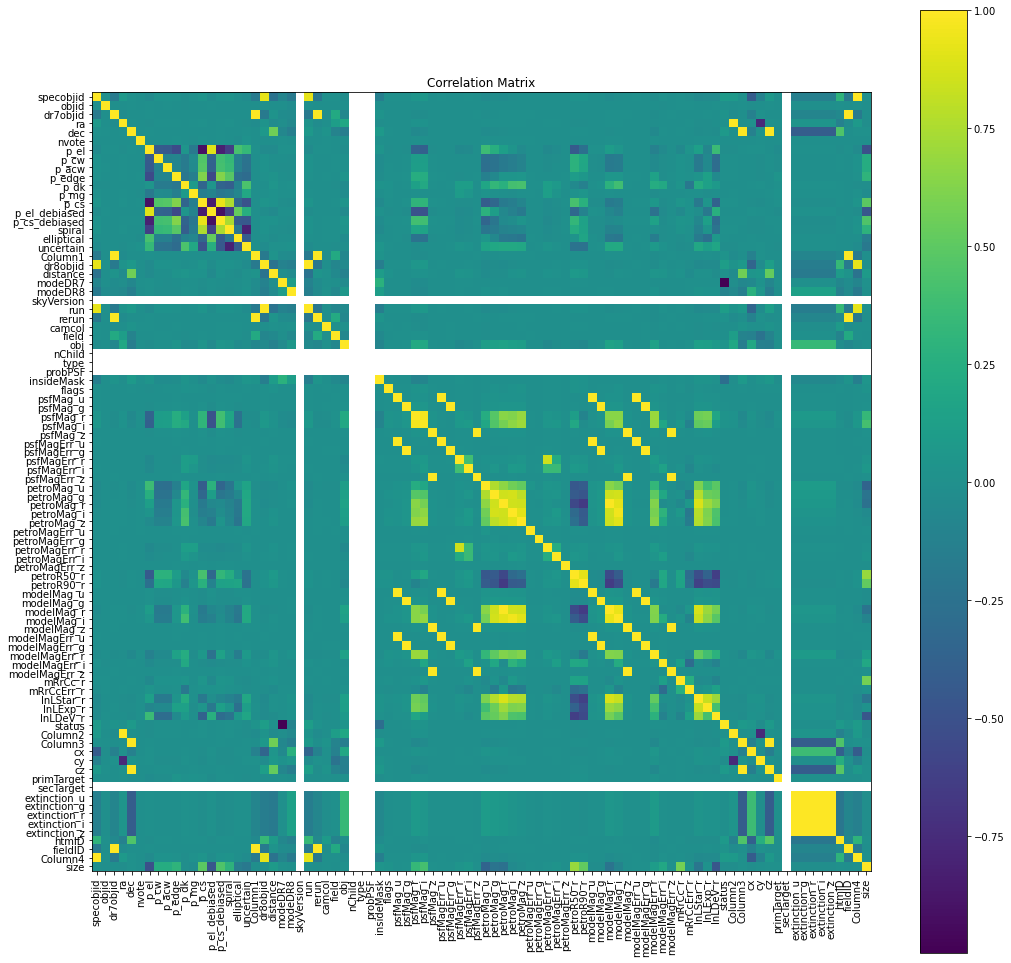

In [5]:
corr_matrix = df.corr()

# fig, ax = plt.subplots(figsize=(6, 8))
# fig, ax = plt.subplots(figsize=(12, 16))
fig, ax = plt.subplots(figsize=(15, 19))

im = ax.imshow(corr_matrix, interpolation='nearest')

# labels
ax.set_xticks(np.arange(len(corr_matrix.columns)))
ax.set_yticks(np.arange(len(corr_matrix.columns)))

ax.set_xticklabels(corr_matrix.columns, rotation=90)
ax.set_yticklabels(corr_matrix.columns)

# colorbar
plt.colorbar(im, shrink = 0.7)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

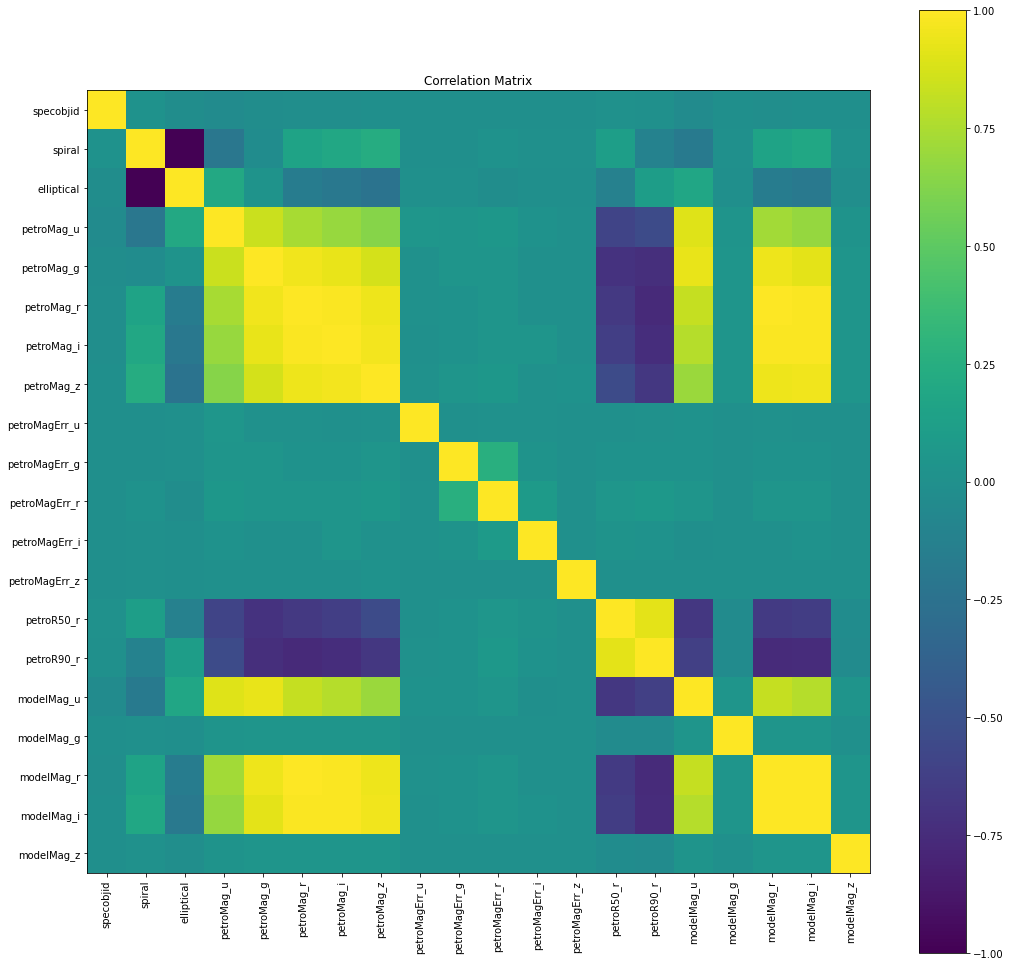

In [169]:
corr_matrix = clean_df.corr()

fig, ax = plt.subplots(figsize=(15, 19))

im = ax.imshow(corr_matrix, interpolation='nearest')

# labels
ax.set_xticks(np.arange(len(corr_matrix.columns)))
ax.set_yticks(np.arange(len(corr_matrix.columns)))

ax.set_xticklabels(corr_matrix.columns, rotation=90)
ax.set_yticklabels(corr_matrix.columns)

# colorbar
plt.colorbar(im, shrink = 0.7)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()